# MetaFL — run all formal analysis steps

Runs MwC 01–05 and then Main 01–10 in one kernel. The formal universe is 12 cortical + 14 limbic ROIs and 168 cross-network edges.


In [1]:
from pathlib import Path
import os

_repo = Path(os.environ.get("METAFL_ROOT", Path.cwd())).resolve()
if not (_repo / "pipeline_steps").is_dir() and (_repo.parent / "pipeline_steps").is_dir():
    _repo = _repo.parent
if not (_repo / "pipeline_steps").is_dir():
    raise FileNotFoundError("Set METAFL_ROOT to the repository root")
os.environ["METAFL_ROOT"] = str(_repo)
os.chdir(_repo)

def _run_step(relative_path):
    _path = _repo / "pipeline_steps" / relative_path
    _code = compile(_path.read_text(encoding="utf-8"), str(_path), "exec")
    exec(_code, get_ipython().user_ns)


## MwC pipeline


### MwC 01 — setup and AAL3-144 recomputation

Recompute MwC across all 144 retained AAL3 nodes before extracting the formal 26 targets.


In [2]:
_run_step("mwc_01_setup_recompute.py")


,input,size_kib
0,03_compute_normative_sc_mwc.py,12.4
1,session_gcmi_pet_AAL3_144.npz,17095.9
2,normative_SC_top10_mask.npz,53.7
3,subject_level_corticolimbic26_normativeSC10_Mw...,120.9
4,subject_level_AAL3_144_normativeSC10_MwC_wide....,288.0
5,validation_report.json,0.2
6,corticolimbic_12x14_ROI_definition.csv,0.6
7,clinical_data.xlsx,10.9
8,subject_level_corticolimbic26_age_sex_adjusted...,133.5


{
  "full_144": "/Users/freddylee/Desktop/Coding_repository/Python_analysis/metabolism_TRD_release_refresh_20261007/outputs/mwc/recomputed_normative_sc/subject_level_AAL3_144_normativeSC10_MwC_wide.csv.gz",
  "selected_26": "/Users/freddylee/Desktop/Coding_repository/Python_analysis/metabolism_TRD_release_refresh_20261007/outputs/mwc/recomputed_normative_sc/subject_level_corticolimbic26_normativeSC10_MwC_wide.csv",
  "validation": "/Users/freddylee/Desktop/Coding_repository/Python_analysis/metabolism_TRD_release_refresh_20261007/outputs/mwc/recomputed_normative_sc/calculation_validation_report.json"
}
PASS: AAL3-144 normative-SC-constrained MwC recomputed before 26-ROI extraction


,check,passed
0,sessions_253,True
1,retained_AAL3_nodes_144,True
2,fixed_dTOR_normative_SC_edges_1030,True
3,gcmi_floor_bits_0p01,True
4,row_normalization_error_below_1e_12,True
5,all_144_nodes_computed_before_26_extraction,True
6,isolated_nodes_remain_missing,True
7,full_144_matches_validated_reference,True
8,selected_26_matches_validated_reference,True


### MwC 02 — subject-level 26-ROI extraction

Extract and export the 12-cortical + 14-limbic subject-level MwC values.


In [3]:
_run_step("mwc_02_subject_level.py")


,quantity,value
0,upstream paired sessions,253.0
1,clinical sessions,253.0
2,ROIs per session,26.0
3,long-table rows,6578.0
4,all-144 to 26 extraction maximum absolute error,0.0


,node_index,network,AAL3_ID,ROI
0,1,cortical,3,Frontal_Sup_2_L
1,2,cortical,4,Frontal_Sup_2_R
2,3,cortical,5,Frontal_Mid_2_L
3,4,cortical,6,Frontal_Mid_2_R
4,5,cortical,19,Frontal_Sup_Medial_L
5,6,cortical,20,Frontal_Sup_Medial_R
6,7,cortical,21,Frontal_Med_Orb_L
7,8,cortical,22,Frontal_Med_Orb_R
8,9,cortical,25,OFCmed_L
9,10,cortical,26,OFCmed_R


### MwC 03 — deviation maps and spatial replication

Create the formal 26-ROI age/sex-adjusted MwC deviation heatmap and TRD1–TRD2 replication result.


,n_ROIs,cortical_ROIs,limbic_ROIs,TRD1_n,TRD2_n,pearson_r,pearson_p_two_sided,same_direction_agreement,DSC_weighted,MwC_input
0,26,12,14,35,85,0.950756,0.0,0.846154,0.831964,HC-only age/sex residual z scores; 26 ROIs ext...


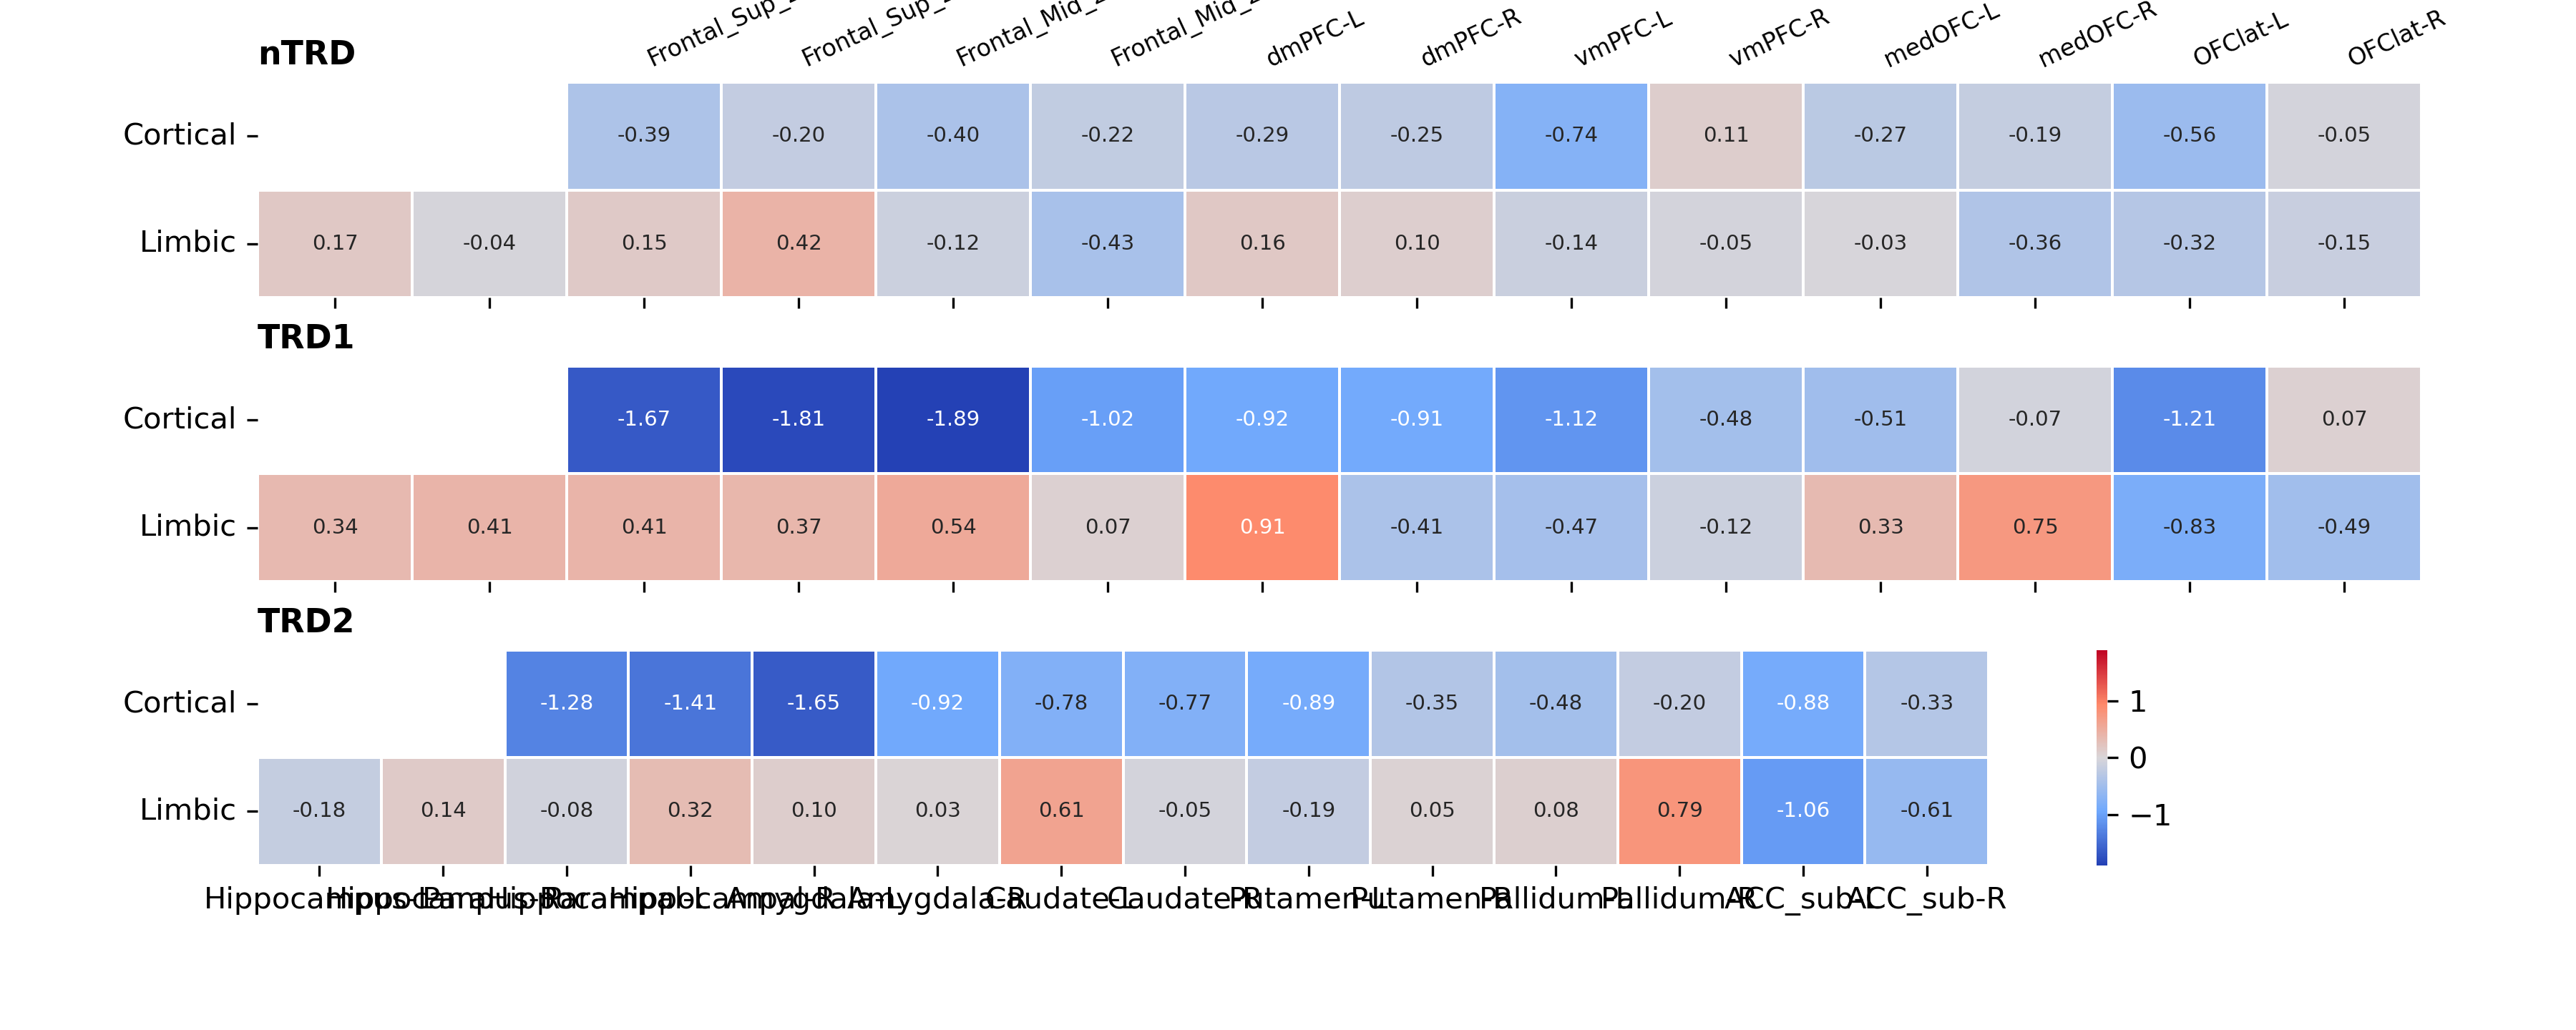

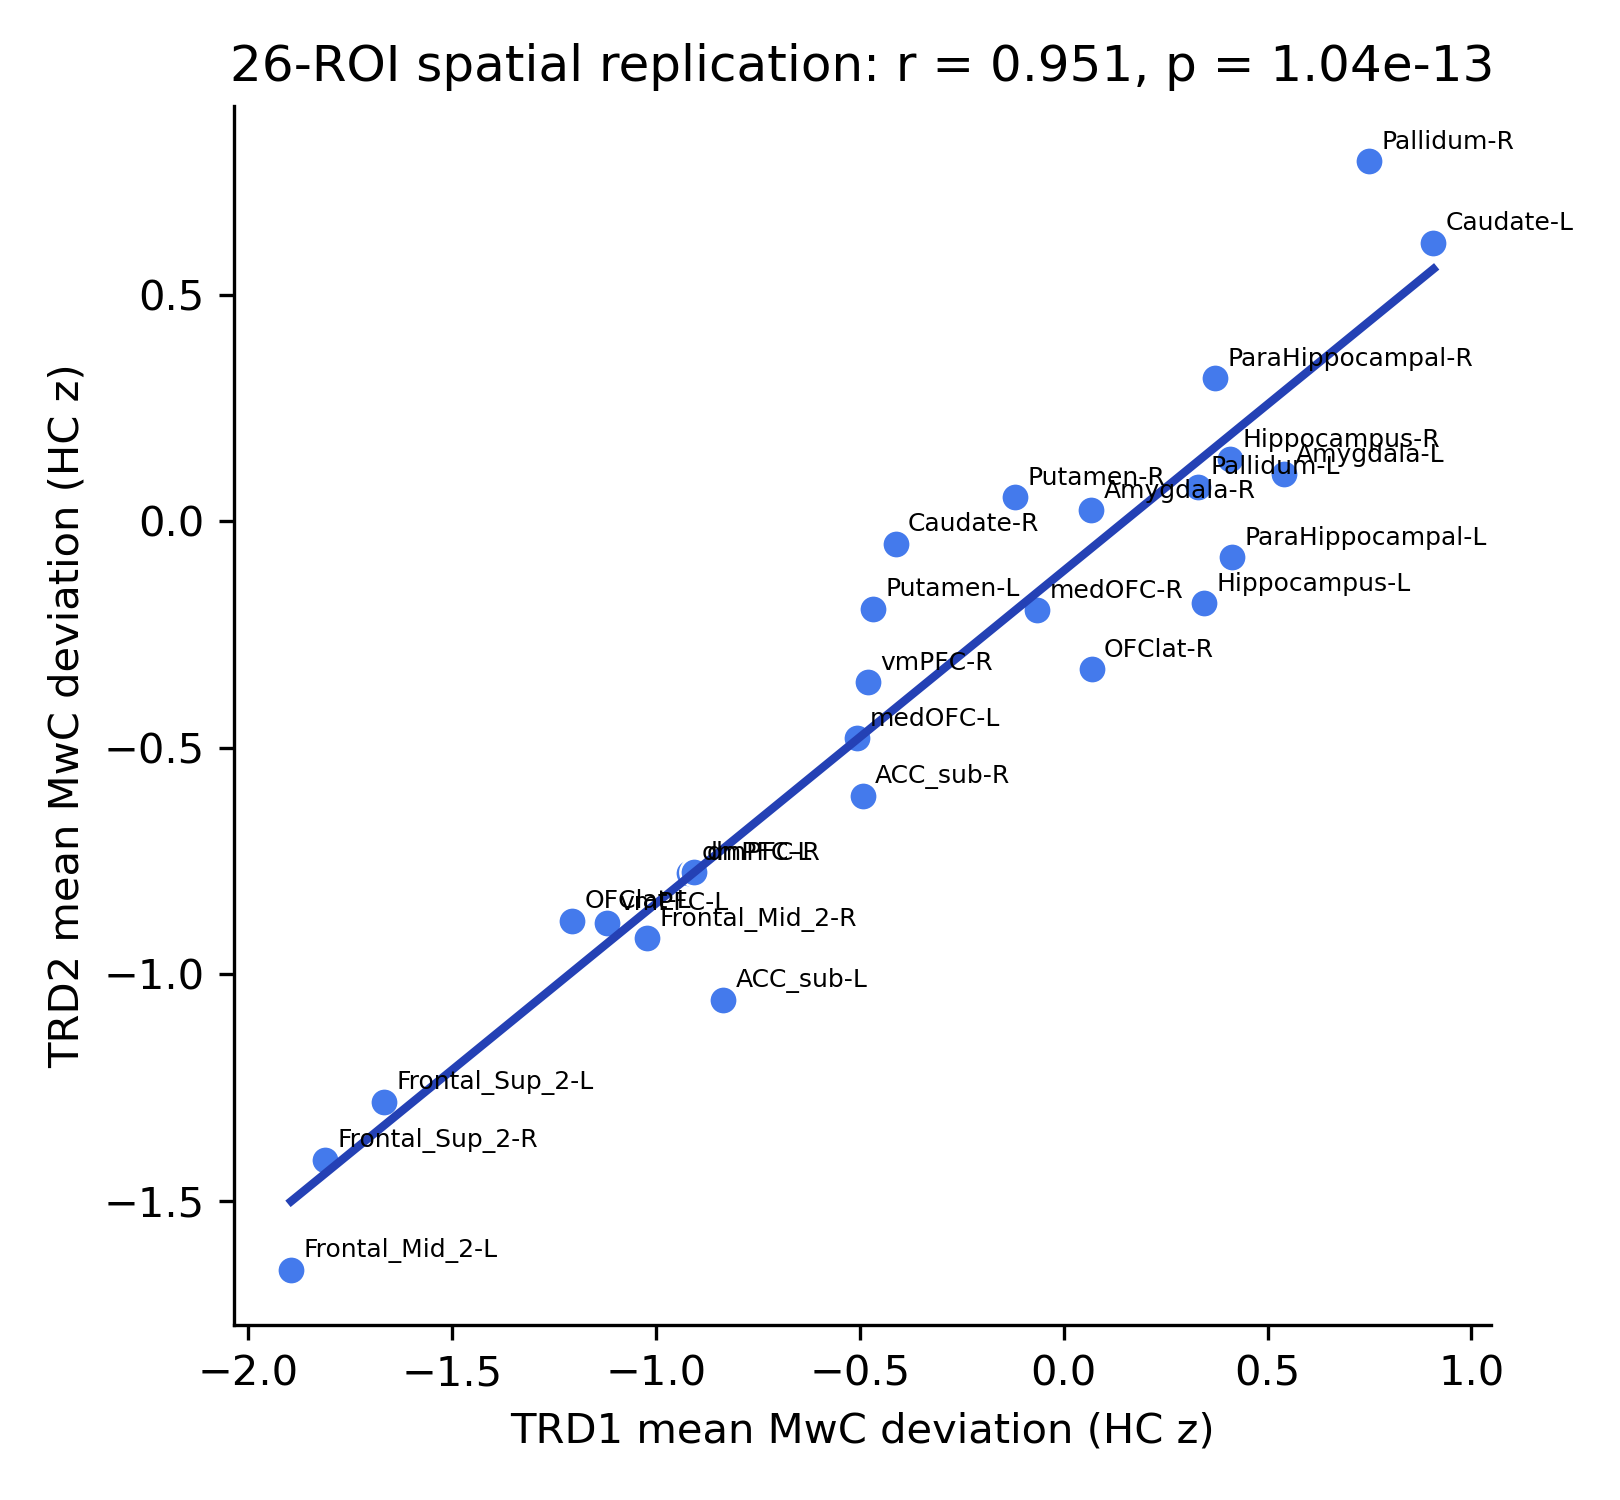

In [4]:
_run_step("mwc_03_deviation_spatial.py")


### MwC 04 — nTRD versus TRD analysis

Test the selected MwC deviations using the formal 26-ROI age/sex-adjusted data.


In [5]:
_run_step("mwc_04_group_analysis.py")


,region,metric,comparison,covariates,n_nTRD,n_TRD,nTRD_mean_HC_z,nTRD_sd_HC_z,TRD_mean_HC_z,TRD_sd_HC_z,beta_TRD_minus_nTRD_HC_SD,hc3_se,ci95_low_TRD_minus_nTRD_HC_SD,ci95_high_TRD_minus_nTRD_HC_SD,p_adjusted
0,SFG_L,MwC_deviation_Frontal_Sup_2_L,TRD - nTRD,age + sex,25,35,-0.392507,1.208856,-1.666740,2.002653,-1.275234,0.395321,-2.050048,-0.500419,0.001256
1,MFG_L,MwC_deviation_Frontal_Mid_2_L,TRD - nTRD,age + sex,25,35,-0.403144,1.679665,-1.893879,1.886119,-1.511057,0.423559,-2.341218,-0.680896,0.000360
2,vmPFC_R,MwC_deviation_Frontal_Med_Orb_R,TRD - nTRD,age + sex,25,35,0.114952,1.469150,-0.479734,1.127049,-0.692292,0.375222,-1.427714,0.043130,0.065035
3,PAL_L,MwC_deviation_Pallidum_L,TRD - nTRD,age + sex,25,34,-0.027443,1.151591,0.330573,1.142455,0.497369,0.282615,-0.056546,1.051283,0.078428
4,HPC_R,MwC_deviation_Hippocampus_R,TRD - nTRD,age + sex,25,35,-0.043946,0.928577,0.409091,1.022139,0.583273,0.248516,0.096191,1.070354,0.018924
5,AMY_R,MwC_deviation_Amygdala_R,TRD - nTRD,age + sex,25,35,-0.430192,0.982046,0.067972,0.769642,0.465657,0.217533,0.039300,0.892014,0.032304


### MwC 05 — figures and audit

Create the selected MwC raincloud figure and audit the five-step MwC workflow.


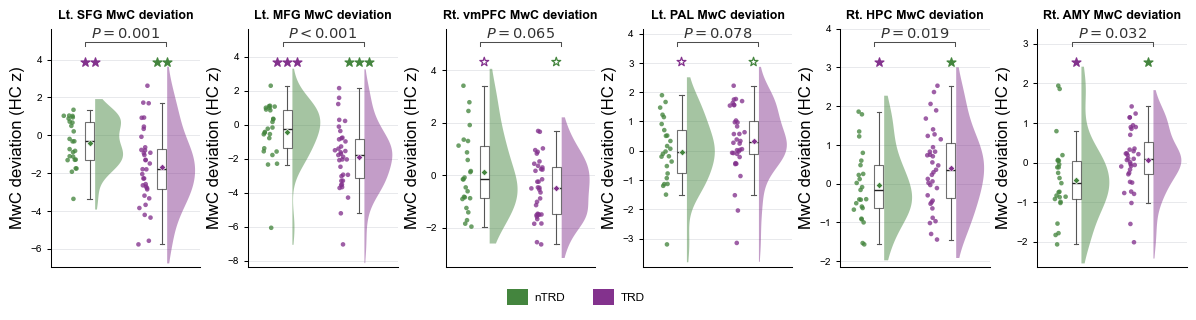

Wrote:
 - /Users/freddylee/Desktop/Coding_repository/Python_analysis/metabolism_TRD_release_refresh_20261007/outputs/mwc/figures/Figure_selected_unilateral_MwC_deviation_raincloud.png
 - /Users/freddylee/Desktop/Coding_repository/Python_analysis/metabolism_TRD_release_refresh_20261007/outputs/mwc/figures/Figure_selected_unilateral_MwC_deviation_raincloud.pdf
 - /Users/freddylee/Desktop/Coding_repository/Python_analysis/metabolism_TRD_release_refresh_20261007/outputs/mwc/figures/Figure_selected_unilateral_MwC_deviation_raincloud.svg
MwC scope audit passed: 16 normative-SC MwC files.


In [6]:
_run_step("mwc_05_figures_audit.py")


## Main pipeline


### Main 01 — setup, input loading, and validation

Load the formal 12-cortical + 14-limbic ROI definition, clinical/PET inputs, 26-node MwC data, and validate 168 cross-network edges.


In [7]:
_run_step("main_01_setup_load.py")


MetaFL package root: /Users/freddylee/Desktop/Coding_repository/Python_analysis/metabolism_TRD_release_refresh_20261007
Main-analysis output root: /Users/freddylee/Desktop/Coding_repository/Python_analysis/metabolism_TRD_release_refresh_20261007/outputs/main_analyses
Cortical IDs: [3, 4, 5, 6, 19, 20, 21, 22, 25, 26, 31, 32]
Limbic IDs: [41, 42, 43, 44, 45, 46, 75, 76, 77, 78, 79, 80, 151, 152]
Cross-edge family: 168


,cohort,clinical_n,ses01_complete_n
0,HC,23,23
1,nTRD,25,25
2,TRD1,35,35
3,TRD2,85,85


,cohort,baseline_n,metric
0,nTRD,25,age/sex-adjusted normative-SC MwC deviation z
1,TRD1,35,age/sex-adjusted normative-SC MwC deviation z
2,TRD2,85,age/sex-adjusted normative-SC MwC deviation z


### Main 02 — demographics and HC reference

Build the HC references and subject-level regional SUVR and 12×14 metabolic-connectivity deviations.


In [8]:
_run_step("main_02_demographics_hc_reference.py")


Written: /Users/freddylee/Desktop/Coding_repository/Python_analysis/metabolism_TRD_release_refresh_20261007/outputs/main_analyses/demographic_and_clinical_summary.xlsx


,variable,HC,nTRD,TRD1,TRD2,primary_test,primary_p_value,TRD1_vs_TRD2_test,TRD1_vs_TRD2_p_value
0,Age,50.91 (17.04); n=23,52.32 (12.22); n=25,48.20 (15.52); n=35,38.40 (14.43); n=85,"one-way ANOVA: HC, nTRD, TRD1",0.561396,Welch t-test,0.002155
1,"Female, n (%)",14 (60.87%); n=23,14 (56.00%); n=25,25 (71.43%); n=35,54 (63.53%); n=85,"Pearson chi-square: HC, nTRD, TRD1",0.443311,Fisher exact test,0.525990
2,Education,14.17 (3.46); n=23,13.44 (3.86); n=25,13.14 (3.83); n=35,14.49 (2.97); n=85,"one-way ANOVA: HC, nTRD, TRD1",0.587829,Welch t-test,0.067189


,variable,nTRD,TRD1,TRD2,primary_test,primary_p_value,TRD1_vs_TRD2_test,TRD1_vs_TRD2_p_value
0,Baseline HDRS-17,3.72 (3.22); n=25,15.89 (7.38); n=35,22.84 (5.19); n=85,Welch t-test: nTRD versus TRD1,1.726193e-11,Welch t-test,0.000006


,variable,note
0,MSM scores,Not required for the released analyses


,variable,iTBS,rTMS,sham,test,statistic,df_1,df_2,p_value
0,HDRS reduction (baseline - post),7.10 (8.18); n=31,8.86 (6.67); n=28,6.23 (5.17); n=26,ordinary one-way ANOVA,1.035219,2,82,0.359743


,variable,rTMS,iTBS,sham,test,p_value
0,"Age, years",38.29 (11.61); n=28,37.35 (15.40); n=31,39.77 (16.32); n=26,one-way ANOVA,0.822937
1,"Female, n (%)",17 (60.71%); n=28,20 (64.52%); n=31,17 (65.38%); n=26,Pearson chi-square,0.928941
2,"Education, years",14.64 (2.64); n=28,14.06 (2.68); n=31,14.85 (3.61); n=26,one-way ANOVA,0.586351
3,Baseline HDRS-17,22.46 (4.88); n=28,23.19 (5.35); n=31,22.81 (5.48); n=26,one-way ANOVA,0.866991
4,HDRS-17 reduction,8.86 (6.67); n=28,7.10 (8.18); n=31,6.23 (5.17); n=26,one-way ANOVA,0.359743


### Main 03 — baseline discovery and sensitivity

Run nTRD-versus-TRD baseline regional, connectivity, MwC, and baseline-severity sensitivity analyses.


In [9]:
_run_step("main_03_baseline_discovery_sensitivity.py")


,modality,tested_n,primary_p_lt_0p01,HDRS_adjusted_p_lt_0p01,retained,lost,new
0,edge,168,19,2,1,18,1
1,regional,26,8,3,3,5,0
2,MwC,26,3,0,0,3,0


TRD2 subject-level deviations: (85, 168) (85, 26)


### Main 04 — longitudinal paired and clinical analyses

Run iTBS, rTMS, and sham paired analyses plus prespecified clinical correlations.


In [10]:
_run_step("main_04_longitudinal_paired_clinical.py")


Longitudinal edge archive: /Users/freddylee/Desktop/Coding_repository/Python_analysis/metabolism_TRD_release_refresh_20261007/outputs/main_analyses/02_TRD2_deviation_prepost_agesex/longitudinal_high_quality_PET_subject_matrices_cross168.npz


,arm,n,edge_prepost_uncorrected_p_lt_0p05,edge_HDRS_FDR_q_lt_0p05_primary,edge_HDRS_uncorrected_p_lt_0p05_exploratory,regional_prepost_uncorrected_p_lt_0p05,regional_HDRS_FDR_q_lt_0p05_primary,regional_HDRS_uncorrected_p_lt_0p05_exploratory
0,iTBS,31,15,0,0,0,0,0
1,rTMS,28,13,0,2,0,0,0
2,sham,26,1,0,0,3,0,0


### Main 05 — group-by-time and MwC analyses

Run group-by-time models and the formal 26-ROI age/sex-adjusted MwC analysis.


In [11]:
_run_step("main_05_interactions_mwc.py")


,active_arm,modality,ROI_1,ROI_2,active_n,active_pre_mean_deviation,active_post_mean_deviation,active_post_minus_pre,active_change_CI95_low,active_change_CI95_high,active_Cohen_dz,active_paired_t,active_paired_p_uncorrected,sham_n,sham_pre_mean_deviation,sham_post_mean_deviation,sham_post_minus_pre,sham_change_CI95_low,sham_change_CI95_high,sham_Cohen_dz,sham_paired_t,sham_paired_p_uncorrected,interaction_beta_active_minus_sham,interaction_CI95_low,interaction_CI95_high,interaction_t,interaction_effect_size_partial_r,interaction_df_resid,interaction_p_uncorrected,interaction_n,interaction_residual_shapiro_W_descriptive,interaction_residual_shapiro_p_descriptive,interaction_breusch_pagan_p_descriptive,interaction_q_fdr_BH_within_arm_modality
0,iTBS,edge,AAL3_006_Frontal_Mid_2_R,AAL3_079_Pallidum_L,31,-2.314258,-1.599745,0.714513,0.091649,1.337376,0.420775,2.342777,0.025966,26,-1.432814,-1.924811,-0.491997,-1.460498,0.476504,-0.205185,-1.046243,0.305460,1.175698,0.070350,2.281045,2.133403,0.281219,53.0,0.037539,57,0.960810,6.212722e-02,0.113478,0.301137
1,iTBS,edge,AAL3_031_OFClat_L,AAL3_151_ACC_sub_L,31,0.299379,-0.127256,-0.426636,-0.750761,-0.102511,-0.482812,-2.688181,0.011610,26,0.024298,0.098233,0.073935,-0.271506,0.419375,0.086449,0.440803,0.663144,-0.496325,-0.969502,-0.023148,-2.103867,-0.277628,53.0,0.040152,57,0.954900,3.295820e-02,0.966708,0.301137
2,iTBS,edge,AAL3_031_OFClat_L,AAL3_041_Hippocampus_L,31,-0.194847,-0.482488,-0.287641,-0.450633,-0.124648,-0.647316,-3.604102,0.001119,26,-0.452435,-0.374626,0.077809,-0.336174,0.491791,0.075915,0.387093,0.701963,-0.378085,-0.788152,0.031982,-1.849313,-0.246203,53.0,0.069993,57,0.883366,5.202672e-05,0.076932,0.349963
3,iTBS,edge,AAL3_005_Frontal_Mid_2_L,AAL3_046_Amygdala_R,31,0.736546,-0.100241,-0.836787,-1.522689,-0.150885,-0.447493,-2.491533,0.018475,26,0.008876,0.239097,0.230221,-0.980612,1.441055,0.076797,0.391589,0.698680,-1.019041,-2.323776,0.285694,-1.566553,-0.210367,53.0,0.123171,57,0.904916,2.887895e-04,0.083690,0.390642
4,iTBS,edge,AAL3_026_OFCmed_R,AAL3_078_Putamen_R,31,-0.589434,0.156725,0.746159,0.195418,1.296901,0.496954,2.766924,0.009597,26,-0.894420,-0.818804,0.075616,-0.567006,0.718238,0.047527,0.242342,0.810492,0.638596,-0.194692,1.471884,1.537117,0.206585,53.0,0.130214,57,0.918018,8.941176e-04,0.724611,0.390642
5,iTBS,edge,AAL3_025_OFCmed_L,AAL3_043_ParaHippocampal_L,31,-0.280652,-0.650436,-0.369783,-0.723282,-0.016285,-0.383701,-2.136355,0.040926,26,-0.556192,-0.578550,-0.022357,-0.374096,0.329381,-0.025674,-0.130910,0.896894,-0.335269,-0.835860,0.165322,-1.343340,-0.181459,53.0,0.184886,57,0.906307,3.245046e-04,0.822976,0.402448
6,iTBS,edge,AAL3_020_Frontal_Sup_Medial_R,AAL3_151_ACC_sub_L,31,-0.739533,-1.365939,-0.626407,-1.164504,-0.088310,-0.427001,-2.377440,0.024008,26,-1.812052,-1.663599,0.148453,-0.990328,1.287233,0.052654,0.268483,0.790530,-0.785263,-1.965683,0.395156,-1.334304,-0.180278,53.0,0.187809,57,0.910482,4.626455e-04,0.052038,0.402448
7,iTBS,edge,AAL3_026_OFCmed_R,AAL3_080_Pallidum_R,31,-1.223280,-0.559661,0.663619,0.122167,1.205071,0.449564,2.503068,0.017987,26,-1.400816,-1.219093,0.181723,-0.427146,0.790591,0.120550,0.614689,0.544314,0.408471,-0.352018,1.168959,1.077319,0.146387,53.0,0.286217,57,0.922576,1.348226e-03,0.513616,0.438759
8,iTBS,edge,AAL3_005_Frontal_Mid_2_L,AAL3_042_Hippocampus_R,31,0.292911,-0.448726,-0.741637,-1.428218,-0.055056,-0.396216,-2.206038,0.035181,26,-0.305960,-0.428642,-0.122681,-1.154950,0.909588,-0.048003,-0.244768,0.808634,-0.626722,-1.820570,0.567127,-1.052935,-0.143142,53.0,0.297148,57,0.934014,3.944011e-03,0.061896,0.438759
9,iTBS,edge,AAL3_003_Frontal_Sup_2_L,AAL3_046_Amygdala_R,31,0.246742,-0.373249,-0.619991,-1.215889,-0.024093,-0.381633,-2.124845,0.041951,26,-0.291082,-0.328936,-0.037854,-1.028763,0.953054,-0.015430,-0.078678,0.937915,-0.553050,-1.635331,0.529230,-1.024945,-0.139412,53.0,0.310044,57,0.904956,2.897531e-04,0.147141,0.438759


                      analysis  arm                       family  tested  nominal_p_lt_0p05  fdr_q_lt_0p05                                                                                         method
         baseline TRD1 vs nTRD TRD1               26 MwC targets      26                  8              0                                                                             HC3 OLS; age + sex
               paired pre-post iTBS               26 MwC targets      26                  1              0                                                                       paired t; post minus pre
               paired pre-post rTMS               26 MwC targets      26                  2              0                                                                       paired t; post minus pre
               paired pre-post sham               26 MwC targets      26                  2              0                                                                       paired t; post 

,modality


,modality,arm,paired_node_index,paired_network,paired_AAL3_ID,ROI,display_roi,paired_n_paired,paired_pre_mean_deviation_HC_z,paired_pre_SD_deviation_HC_z,paired_post_mean_deviation_HC_z,paired_post_SD_deviation_HC_z,paired_post_minus_pre_HC_z,paired_change_ci95_low,paired_change_ci95_high,paired_paired_t,paired_paired_df,paired_effect_size_Cohen_dz,paired_paired_p_uncorrected,paired_change_shapiro_W,...,interaction_covariates,interaction_model,interaction_interaction_q_fdr_BH_26_nodes,interaction_interaction_nominal_p_lt_0p05,interaction_interaction_fdr_q_lt_0p05,HDRS_node_index,HDRS_network,HDRS_AAL3_ID,HDRS_n_used,HDRS_HDRS_improvement_definition,HDRS_MwC_change_definition,HDRS_partial_Spearman_r,HDRS_partial_Spearman_p_uncorrected,HDRS_covariates,HDRS_paired_p_uncorrected,HDRS_paired_nominal_p_lt_0p05,HDRS_partial_Spearman_q_fdr_BH_26_nodes,HDRS_HDRS_nominal_p_lt_0p05,HDRS_HDRS_fdr_q_lt_0p05,HDRS_paired_and_HDRS_nominal_p_lt_0p05
0,MwC,iTBS,16,limbic,44,ParaHippocampal_R,PHG-R,31,0.389801,1.257958,-0.166694,0.842952,-0.556495,-1.019284,-0.093705,-2.455791,30,-0.441073,0.020068,0.981762,...,age + sex,HC3 OLS on post-minus-pre change; equivalent g...,0.422978,False,False,16,limbic,44,31,pre minus post; positive means clinical improv...,post minus pre HC-referenced deviation z,-0.028743,0.882335,age + sex,0.020068,True,0.966008,False,False,False
1,MwC,rTMS,12,cortical,32,OFClat_R,OFClat-R,28,-0.868296,1.029519,-0.244359,1.289997,0.623937,0.151418,1.096455,2.709338,27,0.512017,0.011564,0.972958,...,age + sex,HC3 OLS on post-minus-pre change; equivalent g...,0.182030,True,False,12,cortical,32,28,pre minus post; positive means clinical improv...,post minus pre HC-referenced deviation z,-0.167835,0.412478,age + sex,0.011564,True,0.958074,False,False,False
2,MwC,rTMS,15,limbic,43,ParaHippocampal_L,PHG-L,28,-0.168325,1.028518,0.361014,1.162574,0.529338,0.006234,1.052443,2.076281,27,0.392380,0.047514,0.984907,...,age + sex,HC3 OLS on post-minus-pre change; equivalent g...,0.358028,False,False,15,limbic,43,28,pre minus post; positive means clinical improv...,post minus pre HC-referenced deviation z,0.408485,0.038284,age + sex,0.047514,True,0.574443,True,False,True


### Main 06 — spatial replication

Quantify TRD1–TRD2 spatial replication for 26 regional, 168 connectivity, and 26 MwC features.


In [12]:
_run_step("main_06_spatial_replication_report.py")


,modality,display_name,n_TRD1,n_TRD2,n_features,metric,estimate,parametric_p_descriptive,empirical_p_one_sided,null_mean,null_95th_percentile,significance_threshold_alpha_0_05,threshold_operator,threshold_exceeded,significant_at_alpha_0_05,same_direction_count,permutation_resamples,permutation_exact,permutation_seed,permutation_scheme
0,Regional,Regional SUVR,35,85,26,Pearson correlation,0.975748,2.415339e-17,9.999900e-06,0.000977,0.462838,0.462946,>=,True,True,NaN,100000,False,20260830.0,Monte Carlo permutation of 13 bilateral ROI-pa...
1,Regional,Regional SUVR,35,85,26,Same-direction proportion,0.884615,NaN,1.249988e-03,0.494524,0.730769,0.807692,>=,True,True,23.0,100000,False,20260830.0,Monte Carlo permutation of 13 bilateral ROI-pa...
2,Regional,Regional SUVR,35,85,26,Magnitude-weighted signed DSC,0.747171,NaN,9.999900e-06,0.295392,0.477869,0.477885,>=,True,True,NaN,100000,False,20260830.0,Monte Carlo permutation of 13 bilateral ROI-pa...
3,Connectivity,Metabolic edge,35,85,168,Pearson correlation,0.748013,2.295899e-31,5.511464e-07,0.014065,0.223721,0.223721,>=,True,True,NaN,3628800,True,NaN,Exact independent permutations of six bilatera...
4,Connectivity,Metabolic edge,35,85,168,Same-direction proportion,0.892857,NaN,1.851852e-04,0.802721,0.833333,0.845238,>=,True,True,150.0,3628800,True,NaN,Exact independent permutations of six bilatera...
5,Connectivity,Metabolic edge,35,85,168,Magnitude-weighted signed DSC,0.752092,NaN,2.755732e-07,0.569399,0.617528,0.617528,>=,True,True,NaN,3628800,True,NaN,Exact independent permutations of six bilatera...
6,MwC,MwC,35,85,26,Pearson correlation,0.950756,1.042691e-13,9.999900e-06,0.026559,0.440951,0.440980,>=,True,True,NaN,100000,False,20260831.0,Monte Carlo permutation of 13 bilateral ROI-pa...
7,MwC,MwC,35,85,26,Same-direction proportion,0.846154,NaN,2.759972e-03,0.544320,0.692308,0.769231,>=,True,True,22.0,100000,False,20260831.0,Monte Carlo permutation of 13 bilateral ROI-pa...
8,MwC,MwC,35,85,26,Magnitude-weighted signed DSC,0.808350,NaN,9.999900e-06,0.371168,0.525222,0.525229,>=,True,True,NaN,100000,False,20260831.0,Monte Carlo permutation of 13 bilateral ROI-pa...


,modality,metric,estimate,empirical_p_one_sided,null_mean,null_95th_percentile,significance_threshold_alpha_0_05,threshold_operator,threshold_exceeded,significant_at_alpha_0_05,critical_same_direction_count,critical_same_direction_percent,n_features,alpha,alternative,permutation_resamples,permutation_exact,permutation_seed,permutation_scheme
0,Regional,Same-direction proportion,0.884615,1.249988e-03,0.494524,0.730769,0.807692,>=,True,True,21.0,80.769231,26,0.05,greater,100000,False,20260830.0,Monte Carlo permutation of 13 bilateral ROI-pa...
1,Regional,Magnitude-weighted signed DSC,0.747171,9.999900e-06,0.295392,0.477869,0.477885,>=,True,True,NaN,NaN,26,0.05,greater,100000,False,20260830.0,Monte Carlo permutation of 13 bilateral ROI-pa...
2,Connectivity,Same-direction proportion,0.892857,1.851852e-04,0.802721,0.833333,0.845238,>=,True,True,142.0,84.523810,168,0.05,greater,3628800,True,NaN,Exact independent permutations of six bilatera...
3,Connectivity,Magnitude-weighted signed DSC,0.752092,2.755732e-07,0.569399,0.617528,0.617528,>=,True,True,NaN,NaN,168,0.05,greater,3628800,True,NaN,Exact independent permutations of six bilatera...
4,MwC,Same-direction proportion,0.846154,2.759972e-03,0.544320,0.692308,0.769231,>=,True,True,20.0,76.923077,26,0.05,greater,100000,False,20260831.0,Monte Carlo permutation of 13 bilateral ROI-pa...
5,MwC,Magnitude-weighted signed DSC,0.808350,9.999900e-06,0.371168,0.525222,0.525229,>=,True,True,NaN,NaN,26,0.05,greater,100000,False,20260831.0,Monte Carlo permutation of 13 bilateral ROI-pa...


Combined workbook: /Users/freddylee/Desktop/Coding_repository/Python_analysis/metabolism_TRD_release_refresh_20261007/outputs/main_analyses/all_reported_results.xlsx


,analysis,family_or_tested_n,reporting_rule,reported_n
0,TRD1 vs nTRD edge,168,uncorrected p<0.01,19
1,TRD1 vs nTRD regional,26,uncorrected p<0.01,8
2,HDRS-adjusted sensitivity edge,168,uncorrected p<0.01,2
3,HDRS-adjusted sensitivity regional,26,uncorrected p<0.01,3
4,iTBS edge pre-post,168,paired uncorrected p<0.05,15
5,iTBS edge HDRS,15,BH-FDR q<0.05 primary,0
6,iTBS edge HDRS,15,uncorrected p<0.05 exploratory,0
7,iTBS regional pre-post,26,paired uncorrected p<0.05,0
8,iTBS regional HDRS,0,BH-FDR q<0.05 primary,0
9,iTBS regional HDRS,0,uncorrected p<0.05 exploratory,0


### Main 07 — core figures and heatmaps

Create formal 26-ROI and 12×14 heatmaps plus longitudinal feature figures directly from the unified inputs.


In [13]:
_run_step("main_07_core_figures_heatmaps.py")


Regional heatmap: /Users/freddylee/Desktop/Coding_repository/Python_analysis/metabolism_TRD_release_refresh_20261007/outputs/main_analyses/04_figures/nTRD_TRD1_TRD2_regional26_strip_heatmap.png
MwC heatmap (same renderer): /Users/freddylee/Desktop/Coding_repository/Python_analysis/metabolism_TRD_release_refresh_20261007/outputs/main_analyses/04_figures/nTRD_TRD1_TRD2_age_sex_adjusted_MwC_26ROI_strip_heatmap.png
MwC heatmap input values: /Users/freddylee/Desktop/Coding_repository/Python_analysis/metabolism_TRD_release_refresh_20261007/outputs/main_analyses/04_figures/nTRD_TRD1_TRD2_age_sex_adjusted_MwC_26ROI_strip_heatmap_input_values.csv
Connectivity heatmap: /Users/freddylee/Desktop/Coding_repository/Python_analysis/metabolism_TRD_release_refresh_20261007/outputs/main_analyses/04_figures/nTRD_TRD1_TRD2_corticolimbic12x14_heatmap.png


TRD2 pre-post raincloud: /Users/freddylee/Desktop/Coding_repository/Python_analysis/metabolism_TRD_release_refresh_20261007/outputs/main_analyses/04_figures/TRD2_prepost_raincloud.png
Canonical green HDRS correlation panel (partial Spearman; age/sex): /Users/freddylee/Desktop/Coding_repository/Python_analysis/metabolism_TRD_release_refresh_20261007/outputs/main_analyses/04_figures/TRD2_prepost_HDRS_correlation_panel_green_reference.png


,panel_position,arm,feature_label,ROI_1,ROI_2,partial_Spearman_r_age_sex,partial_Spearman_p_age_sex,n_used,covariates,BH_FDR_q_across_displayed_edges,uncorrected_p_lt_0p05,BH_FDR_q_lt_0p05
0,1,rTMS,Lt.MFG-Rt.PAL,AAL3_005_Frontal_Mid_2_L,AAL3_080_Pallidum_R,0.396327,0.045024,28,age; sex,0.193736,True,False
1,2,rTMS,Lt.vmPFC-Lt.CAU,AAL3_021_Frontal_Med_Orb_L,AAL3_075_Caudate_L,0.357868,0.072651,28,age; sex,0.193736,False,False
2,3,rTMS,Lt.vmPFC-Rt.CAU,AAL3_021_Frontal_Med_Orb_L,AAL3_076_Caudate_R,0.116618,0.570489,28,age; sex,0.651987,False,False
3,4,rTMS,Rt.vmPFC-Rt.CAU,AAL3_022_Frontal_Med_Orb_R,AAL3_076_Caudate_R,0.138656,0.499349,28,age; sex,0.651987,False,False
4,5,rTMS,Rt.vmPFC-Rt.PUT,AAL3_022_Frontal_Med_Orb_R,AAL3_078_Putamen_R,-0.057257,0.781149,28,age; sex,0.781149,False,False
5,6,rTMS,Rt.mOFC-Rt.PUT,AAL3_026_OFCmed_R,AAL3_078_Putamen_R,0.128446,0.531750,28,age; sex,0.651987,False,False
6,7,iTBS,Rt.mOFC-Rt.PUT,AAL3_026_OFCmed_R,AAL3_078_Putamen_R,-0.339926,0.071201,31,age; sex,0.193736,False,False
7,8,iTBS,Lt.lOFC-Lt.HPC,AAL3_031_OFClat_L,AAL3_041_Hippocampus_L,0.122463,0.526821,31,age; sex,0.651987,False,False


### Main 08 — circle diagrams

Create the four formal 26-node/168-edge cross-sectional circle diagrams and run reproducibility checks.


In [14]:
_run_step("main_08_circle_diagrams_checks.py")


Circular connectogram: /Users/freddylee/Desktop/Coding_repository/Python_analysis/metabolism_TRD_release_refresh_20261007/outputs/main_analyses/04_figures/corticolimbic_circular_summary.png
Raw plotting data: /Users/freddylee/Desktop/Coding_repository/Python_analysis/metabolism_TRD_release_refresh_20261007/outputs/main_analyses/04_figures/corticolimbic_circular_plot_data.xlsx
High-quality PET-QC TRD2 core analysis reproduced successfully.


,TRD1_edge_p_lt_0p01,TRD1_regional_p_lt_0p01,iTBS_edge_prepost_p_lt_0p05,iTBS_regional_prepost_p_lt_0p05,rTMS_edge_prepost_p_lt_0p05,rTMS_regional_prepost_p_lt_0p05,sham_edge_prepost_p_lt_0p05,sham_regional_prepost_p_lt_0p05,active_vs_sham_interaction_p_lt_0p05
0,19,8,15,0,13,0,1,3,4


,arm,n,edge_prepost_uncorrected_p_lt_0p05,edge_HDRS_FDR_q_lt_0p05_primary,edge_HDRS_uncorrected_p_lt_0p05_exploratory,regional_prepost_uncorrected_p_lt_0p05,regional_HDRS_FDR_q_lt_0p05_primary,regional_HDRS_uncorrected_p_lt_0p05_exploratory
0,iTBS,31,15,0,0,0,0,0
1,rTMS,28,13,0,2,0,0,0
2,sham,26,1,0,0,3,0,0


,active_arm,modality,ROI_1,ROI_2,active_n,active_pre_mean_deviation,active_post_mean_deviation,active_post_minus_pre,active_change_CI95_low,active_change_CI95_high,active_Cohen_dz,active_paired_t,active_paired_p_uncorrected,sham_n,sham_pre_mean_deviation,sham_post_mean_deviation,sham_post_minus_pre,sham_change_CI95_low,sham_change_CI95_high,sham_Cohen_dz,sham_paired_t,sham_paired_p_uncorrected,interaction_beta_active_minus_sham,interaction_CI95_low,interaction_CI95_high,interaction_t,interaction_effect_size_partial_r,interaction_df_resid,interaction_p_uncorrected,interaction_n,interaction_residual_shapiro_W_descriptive,interaction_residual_shapiro_p_descriptive,interaction_breusch_pagan_p_descriptive,interaction_q_fdr_BH_within_arm_modality
0,iTBS,edge,AAL3_006_Frontal_Mid_2_R,AAL3_079_Pallidum_L,31,-2.314258,-1.599745,0.714513,0.091649,1.337376,0.420775,2.342777,0.025966,26,-1.432814,-1.924811,-0.491997,-1.460498,0.476504,-0.205185,-1.046243,0.305460,1.175698,0.070350,2.281045,2.133403,0.281219,53.0,0.037539,57,0.960810,0.062127,0.113478,0.301137
1,iTBS,edge,AAL3_031_OFClat_L,AAL3_151_ACC_sub_L,31,0.299379,-0.127256,-0.426636,-0.750761,-0.102511,-0.482812,-2.688181,0.011610,26,0.024298,0.098233,0.073935,-0.271506,0.419375,0.086449,0.440803,0.663144,-0.496325,-0.969502,-0.023148,-2.103867,-0.277628,53.0,0.040152,57,0.954900,0.032958,0.966708,0.301137
15,rTMS,edge,AAL3_005_Frontal_Mid_2_L,AAL3_080_Pallidum_R,28,0.445601,-0.616486,-1.062087,-1.805427,-0.318748,-0.554033,-2.931667,0.006789,26,-0.970251,-0.413911,0.556340,-0.260143,1.372823,0.275218,1.403340,0.172815,-1.629051,-2.718029,-0.540074,-3.004695,-0.391085,50.0,0.004147,54,0.958101,0.056669,0.767775,0.053915
16,rTMS,edge,AAL3_022_Frontal_Med_Orb_R,AAL3_078_Putamen_R,28,-0.609059,0.200815,0.809874,0.425701,1.194047,0.817434,4.325453,0.000186,26,-0.748617,-0.653306,0.095311,-0.467613,0.658234,0.068387,0.348709,0.730228,0.687815,0.022945,1.352684,2.077876,0.281935,50.0,0.042875,54,0.946476,0.017518,0.140891,0.248558


,modality,display_name,n_TRD1,n_TRD2,n_features,metric,estimate,parametric_p_descriptive,empirical_p_one_sided,null_mean,null_95th_percentile,significance_threshold_alpha_0_05,threshold_operator,threshold_exceeded,significant_at_alpha_0_05,same_direction_count,permutation_resamples,permutation_exact,permutation_seed,permutation_scheme
0,Regional,Regional SUVR,35,85,26,Pearson correlation,0.975748,2.415339e-17,9.999900e-06,0.000977,0.462838,0.462946,>=,True,True,NaN,100000,False,20260830.0,Monte Carlo permutation of 13 bilateral ROI-pa...
1,Regional,Regional SUVR,35,85,26,Same-direction proportion,0.884615,NaN,1.249988e-03,0.494524,0.730769,0.807692,>=,True,True,23.0,100000,False,20260830.0,Monte Carlo permutation of 13 bilateral ROI-pa...
2,Regional,Regional SUVR,35,85,26,Magnitude-weighted signed DSC,0.747171,NaN,9.999900e-06,0.295392,0.477869,0.477885,>=,True,True,NaN,100000,False,20260830.0,Monte Carlo permutation of 13 bilateral ROI-pa...
3,Connectivity,Metabolic edge,35,85,168,Pearson correlation,0.748013,2.295899e-31,5.511464e-07,0.014065,0.223721,0.223721,>=,True,True,NaN,3628800,True,NaN,Exact independent permutations of six bilatera...
4,Connectivity,Metabolic edge,35,85,168,Same-direction proportion,0.892857,NaN,1.851852e-04,0.802721,0.833333,0.845238,>=,True,True,150.0,3628800,True,NaN,Exact independent permutations of six bilatera...
5,Connectivity,Metabolic edge,35,85,168,Magnitude-weighted signed DSC,0.752092,NaN,2.755732e-07,0.569399,0.617528,0.617528,>=,True,True,NaN,3628800,True,NaN,Exact independent permutations of six bilatera...
6,MwC,MwC,35,85,26,Pearson correlation,0.950756,1.042691e-13,9.999900e-06,0.026559,0.440951,0.440980,>=,True,True,NaN,100000,False,20260831.0,Monte Carlo permutation of 13 bilateral ROI-pa...
7,MwC,MwC,35,85,26,Same-direction proportion,0.846154,NaN,2.759972e-03,0.544320,0.692308,0.769231,>=,True,True,22.0,100000,False,20260831.0,Monte Carlo permutation of 13 bilateral ROI-pa...
8,MwC,MwC,35,85,26,Magnitude-weighted signed DSC,0.808350,NaN,9.999900e-06,0.371168,0.525222,0.525229,>=,True,True,NaN,100000,False,20260831.0,Monte Carlo permutation of 13 bilateral ROI-pa...


### Main 09 — five global indexes

Compute the five global indexes from 26 regional, 168 connectivity, and 26 MwC features and create their figures.


In [15]:
_run_step("main_09_five_global_indexes.py")


Five-index metabolic-signature analysis completed.
Workbook: /Users/freddylee/Desktop/Coding_repository/Python_analysis/metabolism_TRD_release_refresh_20261007/outputs/main_analyses/10_metabolic_signature_five_metrics/metabolic_signature_five_metrics.xlsx
               metric  comparison  n_case  n_control  case_mean  control_mean     beta  ci95_low  ci95_high        t  effect_size_partial_r  p_uncorrected  q_fdr_BH_5_metrics  reported_main_p_lt_0p01
               D_SUVR TRD1 - nTRD      35         25   1.680261      1.093403 0.598340  0.324780   0.871900 4.381562               0.505272       0.000052            0.000261                     True
D_metabolic_signature TRD1 - nTRD      33         25   1.908325      0.072385 1.795273  0.874043   2.716503 3.907065               0.469454       0.000262            0.000656                     True
                MBI_z TRD1 - nTRD      35         25   1.673501      0.302861 1.457958  0.668143   2.247772 3.697880               0.443013     

Wrote PNAS-style five-index raincloud figures:
 - /Users/freddylee/Desktop/Coding_repository/Python_analysis/metabolism_TRD_release_refresh_20261007/outputs/main_analyses/10_metabolic_signature_five_metrics/Figure_five_metric_nTRD_TRD_raincloud.png
 - /Users/freddylee/Desktop/Coding_repository/Python_analysis/metabolism_TRD_release_refresh_20261007/outputs/main_analyses/10_metabolic_signature_five_metrics/Figure_five_metric_nTRD_TRD_raincloud.pdf
 - /Users/freddylee/Desktop/Coding_repository/Python_analysis/metabolism_TRD_release_refresh_20261007/outputs/main_analyses/10_metabolic_signature_five_metrics/Figure_five_metric_nTRD_TRD_raincloud.svg
 - /Users/freddylee/Desktop/Coding_repository/Python_analysis/metabolism_TRD_release_refresh_20261007/outputs/main_analyses/10_metabolic_signature_five_metrics/Figure_five_metric_active_pre_post_raincloud.png
 - /Users/freddylee/Desktop/Coding_repository/Python_analysis/metabolism_TRD_release_refresh_20261007/outputs/main_analyses/10_metabolic_s

### Main 10 — longitudinal circle diagrams and final audit

Create the four formal longitudinal 26-node/168-edge circle diagrams and audit the complete Main pipeline.


In [16]:
_run_step("main_10_longitudinal_sgc_figures_audit.py")


Longitudinal circular summary: /Users/freddylee/Desktop/Coding_repository/Python_analysis/metabolism_TRD_release_refresh_20261007/outputs/main_analyses/04_figures/corticolimbic_circular_longitudinal_summary.png
Longitudinal circular raw data: /Users/freddylee/Desktop/Coding_repository/Python_analysis/metabolism_TRD_release_refresh_20261007/outputs/main_analyses/04_figures/corticolimbic_circular_longitudinal_effects_data.xlsx


,regional_mean_effect,regional_min_effect,regional_max_effect
panel,,,
rTMS post-pre,0.051687,-0.182894,0.342726
iTBS post-pre,0.070055,-0.241910,0.395156
Sham post-pre,-0.052738,-0.610536,0.697331
Active versus sham,0.107542,-0.687630,0.882174


Longitudinal circular connectogram checks passed.


{
  "status": "PASS",
  "scope": "TRD1 versus nTRD 26-ROI SGC circle adjusted for baseline severity",
  "model": "deviation ~ group_TRD1 + age + sex + baseline HDRS-17",
  "effect_displayed": "OLS group coefficient: adjusted TRD1 minus nTRD",
  "regional_nodes": 26,
  "cortical_limbic_edges": 168,
  "n_TRD1": 35,
  "n_nTRD": 25,
  "baseline_HDRS17_by_group": {
    "TRD1": {
      "count": 35,
      "mean": 15.885714285714286,
      "std": 7.383492831076267,
      "min": 0,
      "max": 35
    },
    "nTRD": {
      "count": 25,
      "mean": 3.72,
      "std": 3.2212833881337835,
      "min": 0,
      "max": 13
    }
  },
  "same_renderer_as_original": true,
  "same_node_scale_as_original_four_panels": 1.581855005654741,
  "same_edge_scale_as_original_four_panels": 1.644499100577166,
  "checks": {
    "all_adjusted_node_values_finite": true,
    "all_adjusted_edge_values_finite": true,
    "individual_png_exists": true,
    "five_panel_png_exists": true,
    "node_table_rows_26": true,

{
  "status": "PASS",
  "scope": "All MwC regions selected dynamically at HC3 uncorrected p < 0.01",
  "selection_source": "/Users/freddylee/Desktop/Coding_repository/Python_analysis/metabolism_TRD_release_refresh_20261007/outputs/main_analyses/07_age_sex_adjusted_MwC/tables/baseline_nTRD_vs_TRD1_adjusted_all_26.csv",
  "selection_source_sha256": "7496d59bb0b977f6682caadc1024823d265ab5ebd1b433da048fc886264546e2",
  "selection_threshold": 0.01,
  "selected_region_count": 3,
  "selected_AAL3_IDs_in_p_order": [
    5,
    3,
    4
  ],
  "selected_regions_in_p_order": [
    "Lt. MFG",
    "Lt. SFG",
    "Rt. SFG"
  ],
  "atlas": "/Users/freddylee/Desktop/Coding_repository/Python_analysis/metabolism_TRD_release_refresh_20261007/inputs/core/AAL3_144_space-PET_res-2_dseg.nii.gz",
  "atlas_sha256": "6446a71e6d4ee2d7ee85a58d35039762ba10c0bf605b7ceca020ee36bac0f525",
  "atlas_shape": [
    79,
    95,
    79
  ],
  "union_voxel_count": 14503,
  "rendering": {
    "library": "nilearn.plotting.pl

{
  "status": "PASS",
  "scope": "Bilateral vmPFC, dmPFC, putamen and pallidum coloured by the formal sensitivity-adjusted regional-SUVR group beta",
  "comparison": "TRD1 minus nTRD",
  "covariates": [
    "age",
    "sex",
    "baseline HDRS-17"
  ],
  "all_eight_prespecified_ROIs_displayed": true,
  "display_p_threshold_applied": false,
  "atlas": "/Users/freddylee/Desktop/Coding_repository/Python_analysis/metabolism_TRD_release_refresh_20261007/inputs/core/AAL3_144_space-PET_res-2_dseg.nii.gz",
  "atlas_sha256": "6446a71e6d4ee2d7ee85a58d35039762ba10c0bf605b7ceca020ee36bac0f525",
  "atlas_shape": [
    79,
    95,
    79
  ],
  "atlas_affine": [
    [
      -2.0,
      0.0,
      0.0,
      78.0
    ],
    [
      0.0,
      2.0,
      0.0,
      -112.0
    ],
    [
      0.0,
      0.0,
      2.0,
      -70.0
    ],
    [
      0.0,
      0.0,
      0.0,
      1.0
    ]
  ],
  "result_table": "/Users/freddylee/Desktop/Coding_repository/Python_analysis/metabolism_TRD_release_refresh

{
  "status": "PASS",
  "comparison": "TRD1 minus nTRD",
  "covariates": [
    "age",
    "sex",
    "baseline HDRS-17"
  ],
  "colour_semantics": {
    "prefrontal": "Blue shade intensity encodes absolute adjusted regional-SUVR beta",
    "subcortical": "Categorical structure colours: bilateral caudate #EAD8DE; bilateral putamen and pallidum #D2A1B1",
    "signed_values": "Signed adjusted betas are printed below each figure"
  },
  "display_p_threshold_applied": false,
  "display_mode": "lyrz (four views)",
  "atlas": "/Users/freddylee/Desktop/Coding_repository/Python_analysis/metabolism_TRD_release_refresh_20261007/inputs/core/AAL3_144_space-PET_res-2_dseg.nii.gz",
  "atlas_sha256": "6446a71e6d4ee2d7ee85a58d35039762ba10c0bf605b7ceca020ee36bac0f525",
  "result_table": "/Users/freddylee/Desktop/Coding_repository/Python_analysis/metabolism_TRD_release_refresh_20261007/outputs/main_analyses/11_SGC_26ROI_figures/tables/baseline_severity_adjusted_TRD1_vs_nTRD_regional26_SGC.csv",
  "result

{
  "status": "PASS",
  "renderer": "Nilearn plot_glass_brain",
  "comparison": "TRD1 versus nTRD",
  "quantity": "regional SUVR deviation",
  "covariates": [
    "age",
    "sex"
  ],
  "reporting_threshold": "uncorrected p<.01",
  "display_mode": "lyrz (four views)",
  "plot_abs": false,
  "display_colours_are_categorical": true,
  "statistics_recomputed": false,
  "palette": {
    "lower_regions": "#A3C2F4",
    "higher_non_striatopallidal_regions": "#EAD8DE",
    "higher_putamen_pallidum": "#D2A1B1"
  },
  "source_result_file": "/Users/freddylee/Desktop/Coding_repository/Python_analysis/metabolism_TRD_release_refresh_20261007/outputs/main_analyses/01_TRD1_discovery_agesex/regional_uncorrected_p_lt_0p01.xlsx",
  "source_result_sha256": "05a79982a71f24628fe75736fe2173fc15518a57a47f1d8794015204a26adf77",
  "atlas": "/Users/freddylee/Desktop/Coding_repository/Python_analysis/metabolism_TRD_release_refresh_20261007/inputs/core/AAL3_144_space-PET_res-2_dseg.nii.gz",
  "atlas_sha256": "64

Main-analysis scope audit passed: 187 analytical outputs.


## Results preview

Selected tables and figures from the complete workflow are displayed below. Step-specific notebooks contain the corresponding detailed previews.


### Key tables

**Integrated analysis summary**  
`outputs/main_analyses/all_reported_results.xlsx` — 19 rows × 4 columns

,analysis,family_or_tested_n,reporting_rule,reported_n
0,TRD1 vs nTRD edge,168,uncorrected p<0.01,19
1,TRD1 vs nTRD regional,26,uncorrected p<0.01,8
2,HDRS-adjusted sensitivity edge,168,uncorrected p<0.01,2
3,HDRS-adjusted sensitivity regional,26,uncorrected p<0.01,3
4,iTBS edge pre-post,168,paired uncorrected p<0.05,15
5,iTBS edge HDRS,15,BH-FDR q<0.05 primary,0
6,iTBS edge HDRS,15,uncorrected p<0.05 exploratory,0
7,iTBS regional pre-post,26,paired uncorrected p<0.05,0
8,iTBS regional HDRS,0,BH-FDR q<0.05 primary,0
9,iTBS regional HDRS,0,uncorrected p<0.05 exploratory,0


**TRD1-TRD2 spatial replication**  
`outputs/main_analyses/03_TRD1_TRD2_spatial_correlation/spatial_correlation_summary.csv` — 9 rows × 20 columns

,modality,display_name,n_TRD1,n_TRD2,n_features,metric,estimate,parametric_p_descriptive,empirical_p_one_sided,null_mean,null_95th_percentile,significance_threshold_alpha_0_05,threshold_operator,threshold_exceeded,significant_at_alpha_0_05,same_direction_count,permutation_resamples,permutation_exact,permutation_seed,permutation_scheme
0,Regional,Regional SUVR,35,85,26,Pearson correlation,0.975748,2.415339e-17,9.999900e-06,0.000977,0.462838,0.462946,>=,True,True,NaN,100000,False,20260830.0,Monte Carlo permutation of 13 bilateral ROI-pair labels;...
1,Regional,Regional SUVR,35,85,26,Same-direction proportion,0.884615,NaN,1.249988e-03,0.494524,0.730769,0.807692,>=,True,True,23.0,100000,False,20260830.0,Monte Carlo permutation of 13 bilateral ROI-pair labels;...
2,Regional,Regional SUVR,35,85,26,Magnitude-weighted signed DSC,0.747171,NaN,9.999900e-06,0.295392,0.477869,0.477885,>=,True,True,NaN,100000,False,20260830.0,Monte Carlo permutation of 13 bilateral ROI-pair labels;...
3,Connectivity,Metabolic edge,35,85,168,Pearson correlation,0.748013,2.295899e-31,5.511464e-07,0.014065,0.223721,0.223721,>=,True,True,NaN,3628800,True,NaN,Exact independent permutations of six bilateral frontal ...
4,Connectivity,Metabolic edge,35,85,168,Same-direction proportion,0.892857,NaN,1.851852e-04,0.802721,0.833333,0.845238,>=,True,True,150.0,3628800,True,NaN,Exact independent permutations of six bilateral frontal ...
5,Connectivity,Metabolic edge,35,85,168,Magnitude-weighted signed DSC,0.752092,NaN,2.755732e-07,0.569399,0.617528,0.617528,>=,True,True,NaN,3628800,True,NaN,Exact independent permutations of six bilateral frontal ...
6,MwC,MwC,35,85,26,Pearson correlation,0.950756,1.042691e-13,9.999900e-06,0.026559,0.440951,0.440980,>=,True,True,NaN,100000,False,20260831.0,Monte Carlo permutation of 13 bilateral ROI-pair labels;...
7,MwC,MwC,35,85,26,Same-direction proportion,0.846154,NaN,2.759972e-03,0.544320,0.692308,0.769231,>=,True,True,22.0,100000,False,20260831.0,Monte Carlo permutation of 13 bilateral ROI-pair labels;...
8,MwC,MwC,35,85,26,Magnitude-weighted signed DSC,0.808350,NaN,9.999900e-06,0.371168,0.525222,0.525229,>=,True,True,NaN,100000,False,20260831.0,Monte Carlo permutation of 13 bilateral ROI-pair labels;...


...

,row_source,feature_type,ROI_1_or_region,ROI_2,feature_label,arm,n,pre_mean,post_mean,post_minus_pre,post_minus_pre_CI95_low,post_minus_pre_CI95_high,paired_t,paired_p_uncorrected,Cohen_dz,star_p_lt_0p05
0,rTMS,edge,AAL3_005_Frontal_Mid_2_L,AAL3_080_Pallidum_R,Lt.MFG-Rt.PAL,iTBS,31,-0.356997,-0.066880,0.290116,-0.339666,0.919899,0.940795,0.354324,0.168972,False
1,rTMS,edge,AAL3_005_Frontal_Mid_2_L,AAL3_080_Pallidum_R,Lt.MFG-Rt.PAL,rTMS,28,0.445601,-0.616486,-1.062087,-1.805427,-0.318748,-2.931667,0.006789,-0.554033,True
2,rTMS,edge,AAL3_005_Frontal_Mid_2_L,AAL3_080_Pallidum_R,Lt.MFG-Rt.PAL,sham,26,-0.970251,-0.413911,0.556340,-0.260143,1.372823,1.403340,0.172815,0.275218,False
3,rTMS,edge,AAL3_021_Frontal_Med_Orb_L,AAL3_075_Caudate_L,Lt.vmPFC-Lt.CAU,iTBS,31,-0.557032,-0.745760,-0.188728,-0.867043,0.489587,-0.568223,0.574113,-0.102056,False
4,rTMS,edge,AAL3_021_Frontal_Med_Orb_L,AAL3_075_Caudate_L,Lt.vmPFC-Lt.CAU,rTMS,28,-0.664727,0.058507,0.723234,0.207433,1.239034,2.876991,0.007750,0.543700,True
5,rTMS,edge,AAL3_021_Frontal_Med_Orb_L,AAL3_075_Caudate_L,Lt.vmPFC-Lt.CAU,sham,26,-0.767728,-0.728348,0.039380,-0.596053,0.674813,0.127637,0.899458,0.025032,False
6,rTMS,edge,AAL3_021_Frontal_Med_Orb_L,AAL3_076_Caudate_R,Lt.vmPFC-Rt.CAU,iTBS,31,-2.143062,-1.960475,0.182587,-0.843470,1.208644,0.363423,0.718838,0.065273,False
7,rTMS,edge,AAL3_021_Frontal_Med_Orb_L,AAL3_076_Caudate_R,Lt.vmPFC-Rt.CAU,rTMS,28,-2.540373,-1.088782,1.451591,0.430548,2.472635,2.917035,0.007034,0.551268,True
8,rTMS,edge,AAL3_021_Frontal_Med_Orb_L,AAL3_076_Caudate_R,Lt.vmPFC-Rt.CAU,sham,26,-2.247303,-2.117547,0.129756,-0.682073,0.941584,0.329178,0.744763,0.064557,False
9,rTMS,edge,AAL3_022_Frontal_Med_Orb_R,AAL3_076_Caudate_R,Rt.vmPFC-Rt.CAU,iTBS,31,-1.697275,-1.460485,0.236789,-0.487605,0.961184,0.667576,0.509507,0.119900,False


**Five indexes: nTRD versus TRD**  
`outputs/main_analyses/10_metabolic_signature_five_metrics/TRD1_vs_nonTRD_five_metrics.xlsx` — 5 rows × 14 columns

,metric,comparison,n_case,n_control,case_mean,control_mean,beta,ci95_low,ci95_high,t,effect_size_partial_r,p_uncorrected,q_fdr_BH_5_metrics,reported_main_p_lt_0p01
0,D_SUVR,TRD1 - nTRD,35,25,1.680261,1.093403,0.598340,0.324780,0.871900,4.381562,0.505272,0.000052,0.000261,True
1,D_metabolic_signature,TRD1 - nTRD,33,25,1.908325,0.072385,1.795273,0.874043,2.716503,3.907065,0.469454,0.000262,0.000656,True
2,MBI_z,TRD1 - nTRD,35,25,1.673501,0.302861,1.457958,0.668143,2.247772,3.697880,0.443013,0.000497,0.000828,True
3,D_MwC,TRD1 - nTRD,33,25,1.657961,1.221436,0.411966,0.175779,0.648154,3.496984,0.429704,0.000950,0.001072,True
4,D_MC,TRD1 - nTRD,35,25,1.944924,1.074495,0.889439,0.373007,1.405872,3.450133,0.418688,0.001072,0.001072,True


### Figures

**`outputs/main_analyses/04_figures/nTRD_TRD1_TRD2_regional26_strip_heatmap.png`**

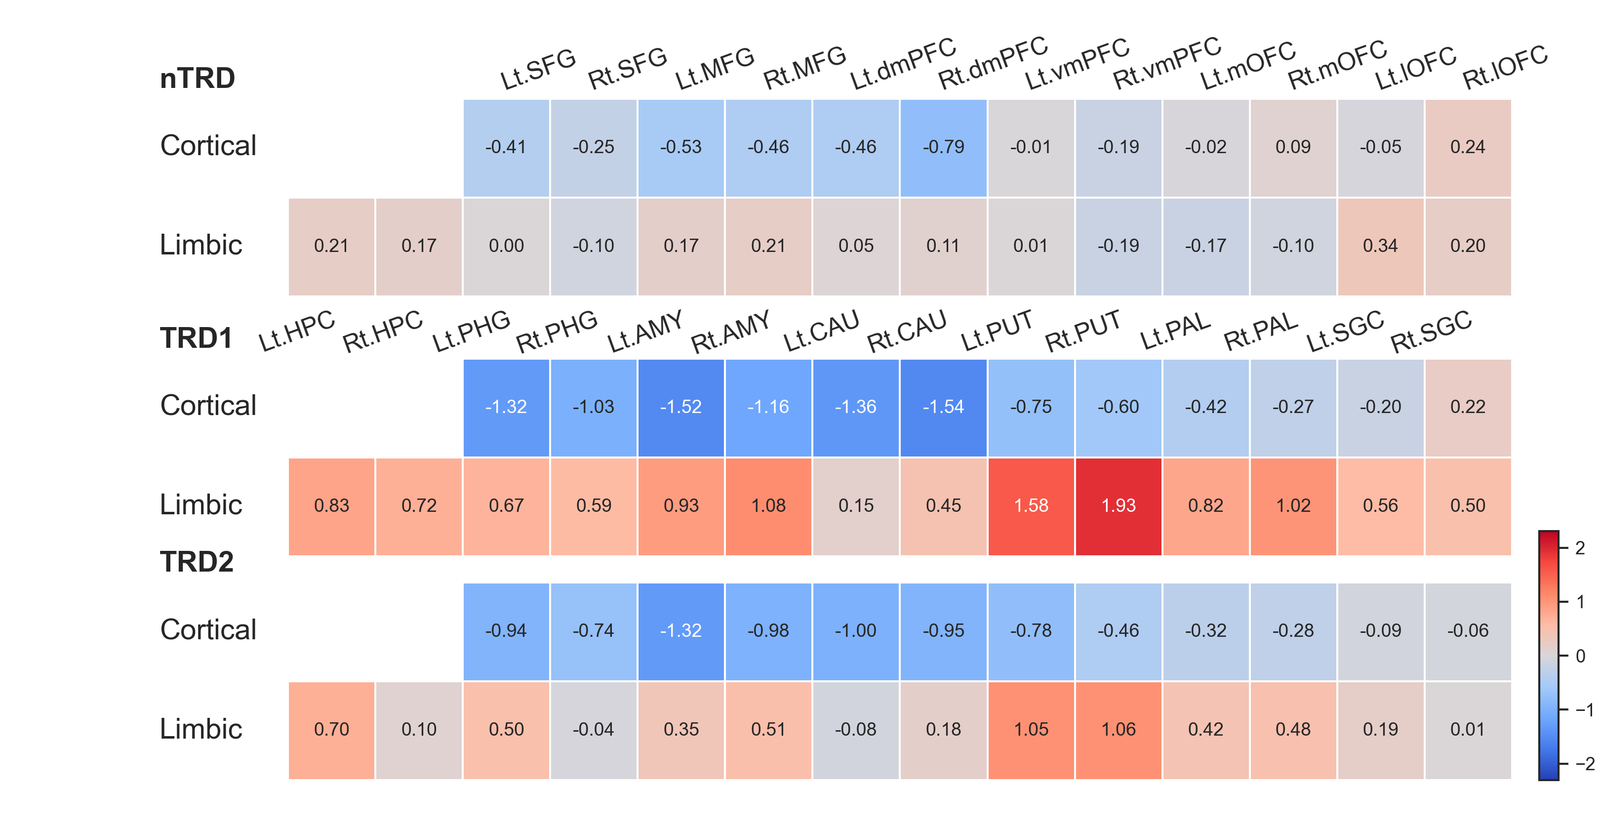

**`outputs/main_analyses/04_figures/nTRD_TRD1_TRD2_corticolimbic12x14_heatmap.png`**

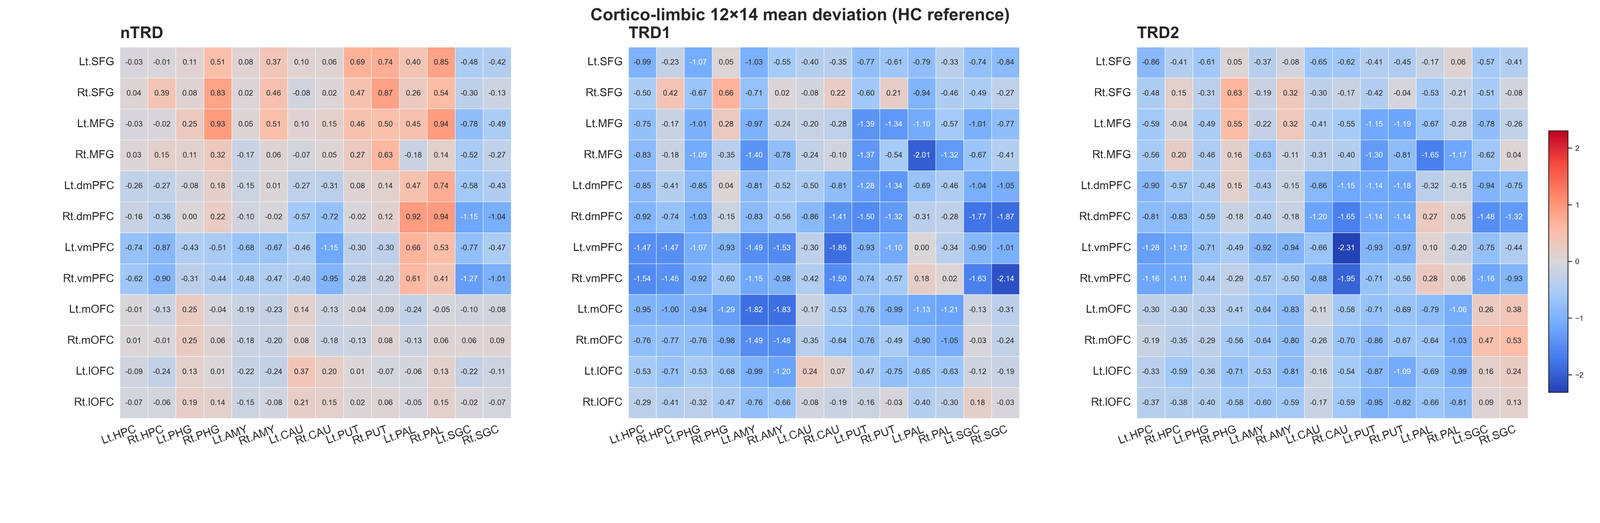

**`outputs/main_analyses/04_figures/nTRD_TRD1_TRD2_age_sex_adjusted_MwC_26ROI_strip_heatmap.png`**

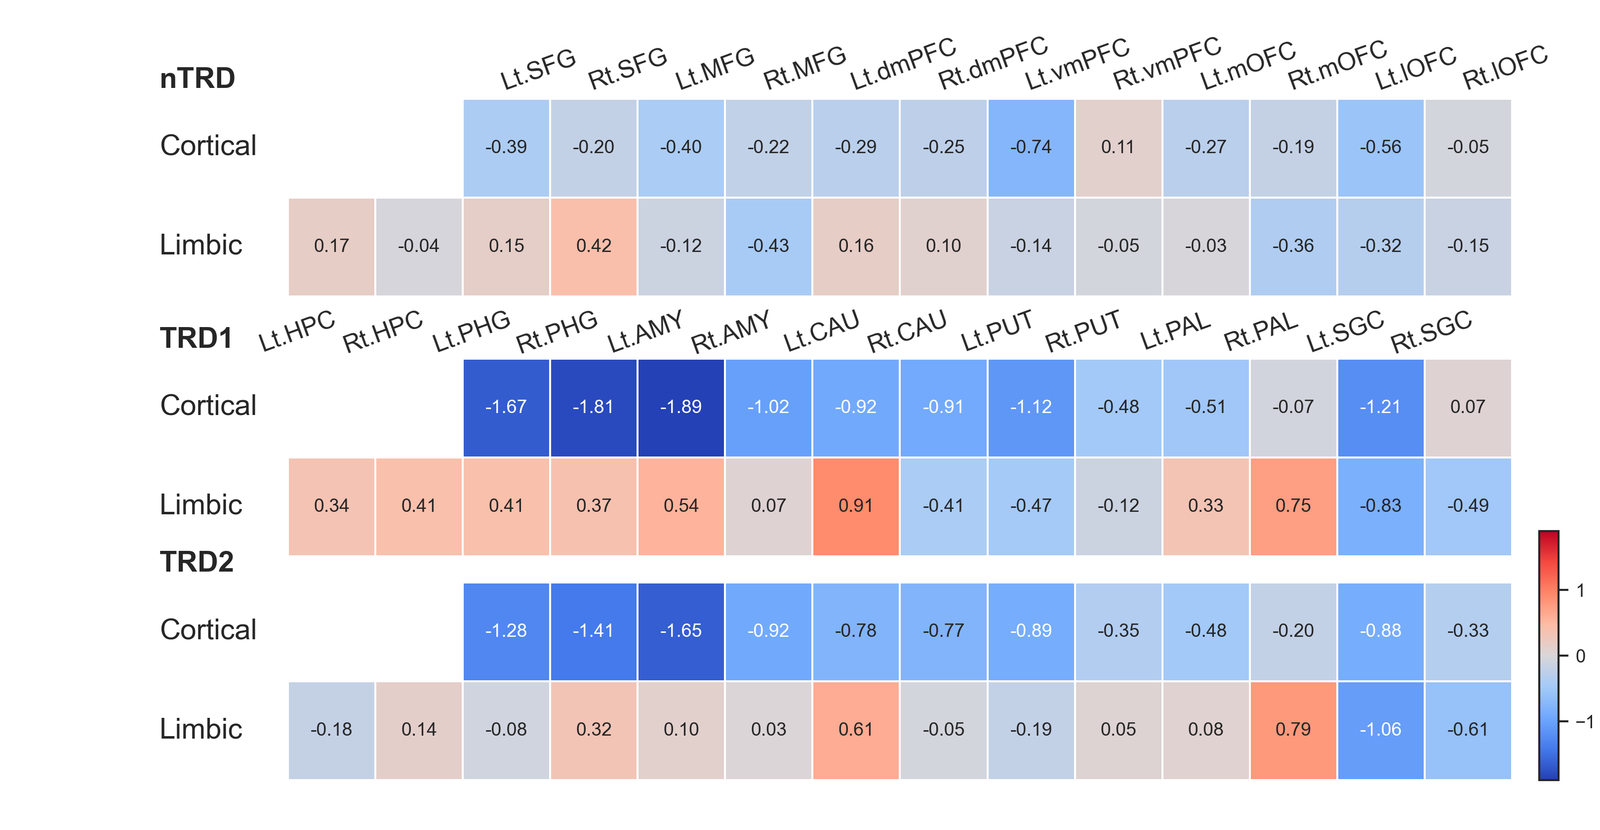

**`outputs/main_analyses/04_figures/corticolimbic_circular_summary.png`**

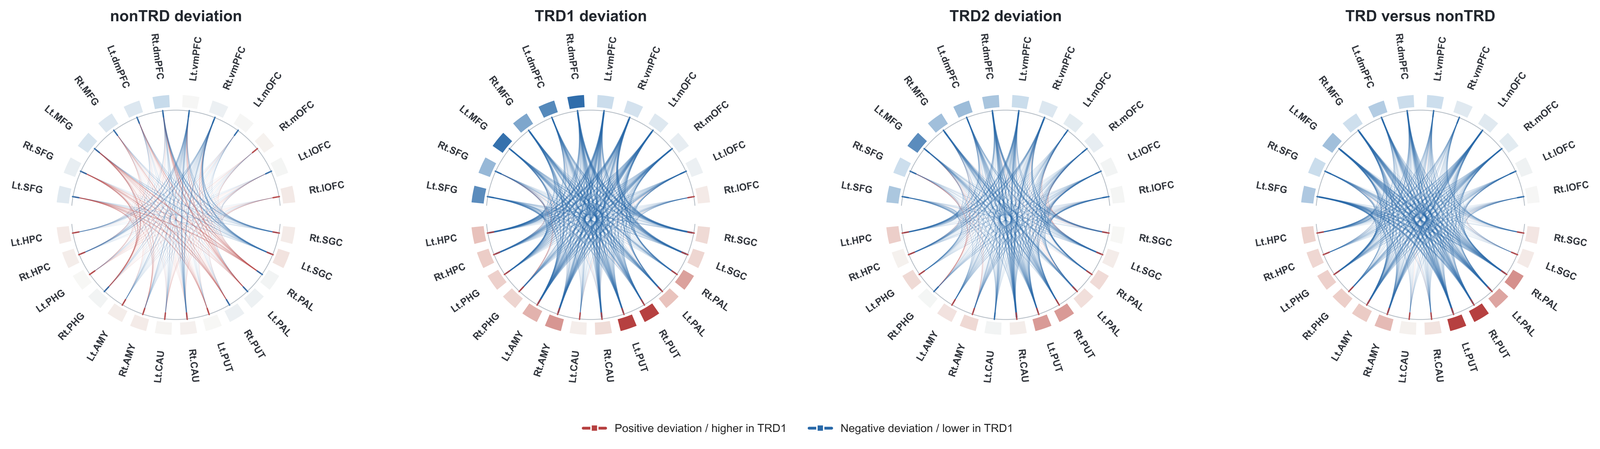

**`outputs/main_analyses/04_figures/TRD2_prepost_raincloud.png`**

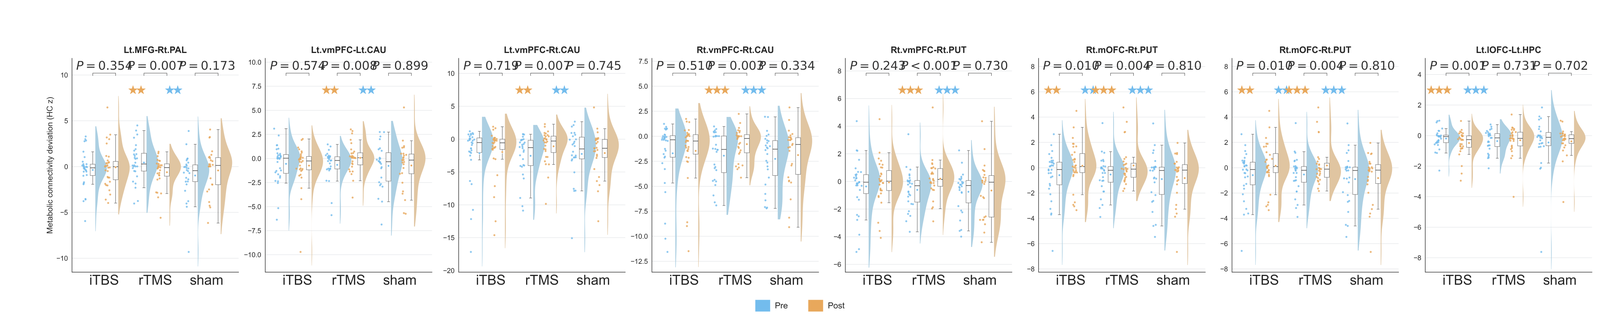

**`outputs/main_analyses/10_metabolic_signature_five_metrics/Figure_five_metric_nTRD_TRD_raincloud.png`**

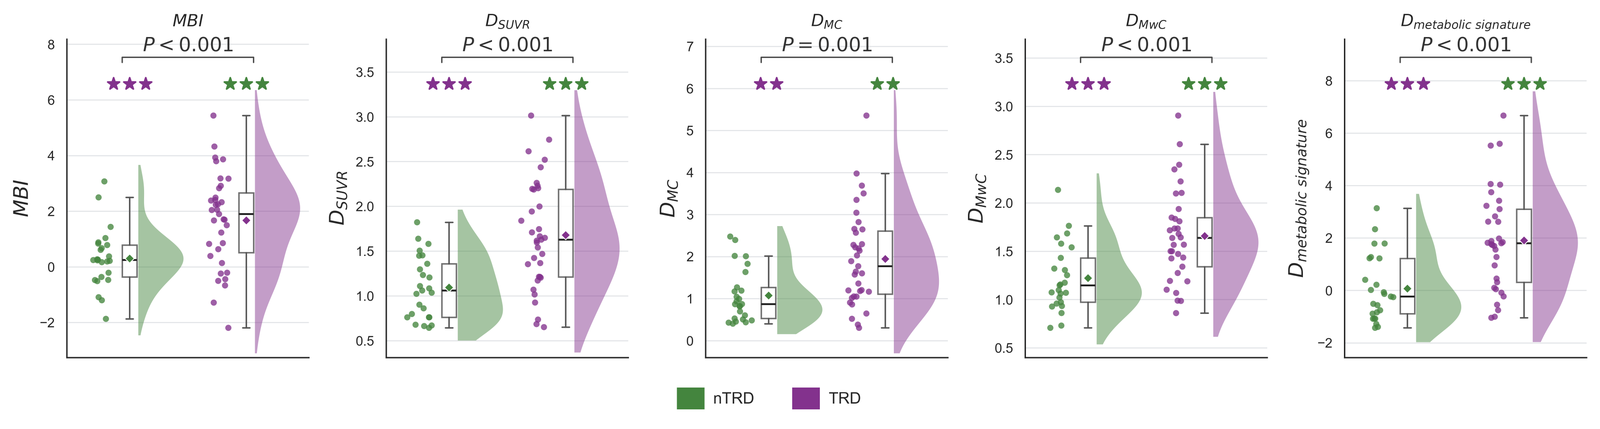

In [17]:
from io import BytesIO
import json as _preview_json
import pandas as _preview_pd
from PIL import Image as PILImage
from IPython.display import Image as NotebookImage, Markdown, display

_inline_table_specs = [{'title': 'Integrated analysis summary', 'path': 'outputs/main_analyses/all_reported_results.xlsx', 'sheet': 'summary', 'max_rows': 30}, {'title': 'TRD1-TRD2 spatial replication', 'path': 'outputs/main_analyses/03_TRD1_TRD2_spatial_correlation/spatial_correlation_summary.csv'}, {'title': 'Longitudinal features used for figures (paired p < .01)', 'path': 'outputs/main_analyses/04_figures/TRD2_prepost_raincloud_data.xlsx', 'sheet': 'paired_tests'}, {'title': 'Five indexes: nTRD versus TRD', 'path': 'outputs/main_analyses/10_metabolic_signature_five_metrics/TRD1_vs_nonTRD_five_metrics.xlsx', 'sheet': 'all_five_metrics'}]
_inline_figure_paths = ['outputs/main_analyses/04_figures/nTRD_TRD1_TRD2_regional26_strip_heatmap.png', 'outputs/main_analyses/04_figures/nTRD_TRD1_TRD2_corticolimbic12x14_heatmap.png', 'outputs/main_analyses/04_figures/nTRD_TRD1_TRD2_age_sex_adjusted_MwC_26ROI_strip_heatmap.png', 'outputs/main_analyses/04_figures/corticolimbic_circular_summary.png', 'outputs/main_analyses/04_figures/TRD2_prepost_raincloud.png', 'outputs/main_analyses/10_metabolic_signature_five_metrics/Figure_five_metric_nTRD_TRD_raincloud.png']

display(Markdown("### Key tables"))
for _table_spec in _inline_table_specs:
    _relative_table = _table_spec["path"]
    _table_path = _repo / _relative_table
    if not _table_path.is_file():
        raise FileNotFoundError(_table_path)
    if _table_path.suffix.lower() == ".csv":
        _preview_table = _preview_pd.read_csv(_table_path)
    elif _table_path.suffix.lower() in {".xlsx", ".xls"}:
        _preview_table = _preview_pd.read_excel(
            _table_path, sheet_name=_table_spec.get("sheet", 0)
        )
    elif _table_path.suffix.lower() == ".json":
        _payload = _preview_json.loads(_table_path.read_text(encoding="utf-8"))
        _checks = _payload.get("checks", _payload)
        _preview_table = _preview_pd.DataFrame(
            {"item": list(_checks), "value": list(_checks.values())}
        ) if isinstance(_checks, dict) else _preview_pd.json_normalize(_payload)
    else:
        raise ValueError(f"Unsupported table format: {_table_path.suffix}")
    if _table_spec.get("query"):
        _preview_table = _preview_table.query(_table_spec["query"]).reset_index(drop=True)
    _max_rows = int(_table_spec.get("max_rows", 40))
    display(Markdown(
        f"**{_table_spec['title']}**  \n"
        f"`{_relative_table}` — {len(_preview_table)} rows × {len(_preview_table.columns)} columns"
    ))
    with _preview_pd.option_context("display.max_columns", 40, "display.max_colwidth", 60):
        display(_preview_table.head(_max_rows))

if _inline_figure_paths:
    display(Markdown("### Figures"))
for _relative_figure in _inline_figure_paths:
    _figure_path = _repo / _relative_figure
    if not _figure_path.is_file():
        raise FileNotFoundError(_figure_path)
    with PILImage.open(_figure_path) as _source_image:
        _preview_image = _source_image.convert("RGB")
        _preview_image.thumbnail((1600, 1200), PILImage.Resampling.LANCZOS)
        _preview_buffer = BytesIO()
        _preview_image.save(_preview_buffer, format="PNG", optimize=True)
    display(Markdown(f"**`{_relative_figure}`**"))
    display(NotebookImage(data=_preview_buffer.getvalue(), format="png"))
